In [1]:
import json
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SeparableConv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping


2025-05-13 20:48:40.865127: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-13 20:48:40.865170: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


In [3]:
# Load the preprocessed dataset
df = pd.read_csv('../../../Edge-IIoTset_DNN-112.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1945449 entries, 0 to 1945448
Data columns (total 99 columns):
 #   Column                     Dtype  
---  ------                     -----  
 0   arp.opcode                 float64
 1   arp.hw.size                float64
 2   icmp.checksum              float64
 3   icmp.seq_le                float64
 4   icmp.transmit_timestamp    float64
 5   http.content_length        float64
 6   http.response              float64
 7   tcp.ack                    float64
 8   tcp.ack_raw                float64
 9   tcp.checksum               float64
 10  tcp.connection.fin         float64
 11  tcp.connection.rst         float64
 12  tcp.connection.syn         float64
 13  tcp.connection.synack      float64
 14  tcp.dstport                float64
 15  tcp.flags                  float64
 16  tcp.flags.ack              float64
 17  tcp.len                    float64
 18  tcp.seq                    float64
 19  udp.port                   float64
 20  ud

In [5]:
df.head(10)

,arp.opcode,arp.hw.size,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,http.content_length,http.response,tcp.ack,tcp.ack_raw,tcp.checksum,...,mqtt1_6,mqtt1_7,mqtt1_8,mqtt1_9,mqtt1_10,mqtt1_11,mqtt1_12,mqtt2_0,mqtt3_0,mqtt3_2
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.400484e+09,38425.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,4.098995e+09,45835.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,17306018.0,1.156158e+09,12740.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14852.0,2.834403e+09,57107.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,3.352177e+09,15227.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15.0,2.492830e+09,49079.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,3.694081e+09,46297.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,59.0,3.652668e+09,1007.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,4.282478e+09,47339.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15.0,4.122899e+09,44739.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0


In [6]:
print(df['Attack_type'].value_counts())

Attack_type
Normal                   1399624
DDoS_UDP                  121567
DDoS_ICMP                  67939
SQL_injection              50826
DDoS_TCP                   50062
Vulnerability_scanner      50026
Password                   49933
DDoS_HTTP                  48544
Uploading                  36957
Backdoor                   24026
Port_Scanning              19977
XSS                        15068
Ransomware                  9689
Fingerprinting               853
MITM                         358
Name: count, dtype: int64


In [7]:
# Creating a dictionary of Types
attacks = {'Normal': 0,'MITM': 1, 'Uploading': 2, 'Ransomware': 3, 'SQL_injection': 4,
       'DDoS_HTTP': 5, 'DDoS_TCP': 6, 'Password': 7, 'Port_Scanning': 8,
       'Vulnerability_scanner': 9, 'Backdoor': 10, 'XSS': 11, 'Fingerprinting': 12,
       'DDoS_UDP': 13, 'DDoS_ICMP': 14}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [8]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_label']

In [9]:
print(df['Attack_type'].value_counts())

Attack_type
0     1399624
13     121567
14      67939
4       50826
6       50062
9       50026
7       49933
5       48544
2       36957
10      24026
8       19977
11      15068
3        9689
12        853
1         358
Name: count, dtype: int64


In [10]:
# Apply the Chi-Squared test
chi_selector = SelectKBest(chi2, k='all')  # Set k to the desired number of features
X_kbest = chi_selector.fit_transform(X, y)

In [11]:
# Get the scores for each feature
chi_scores = chi_selector.scores_

# Combine scores with feature names
chi_scores = pd.DataFrame({'feature': X.columns, 'score': chi_scores})

# Sort the features by their scores
chi_scores = chi_scores.sort_values(by='score', ascending=False)

print(chi_scores)

         feature         score
8    tcp.ack_raw  1.460557e+14
7        tcp.ack  7.606459e+13
18       tcp.seq  7.310061e+12
20    udp.stream  4.093708e+11
22  dns.qry.name  4.196200e+10
..           ...           ...
89       mqtt1_8  1.169939e+00
84       mqtt1_3  7.799595e-01
90       mqtt1_9  7.799595e-01
91      mqtt1_10  7.799595e-01
85       mqtt1_4  7.799595e-01

[97 rows x 2 columns]


/tmp/ipykernel_500712/4000908500.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=chi_scores_top, x='score', y='feature', palette='Blues_r')


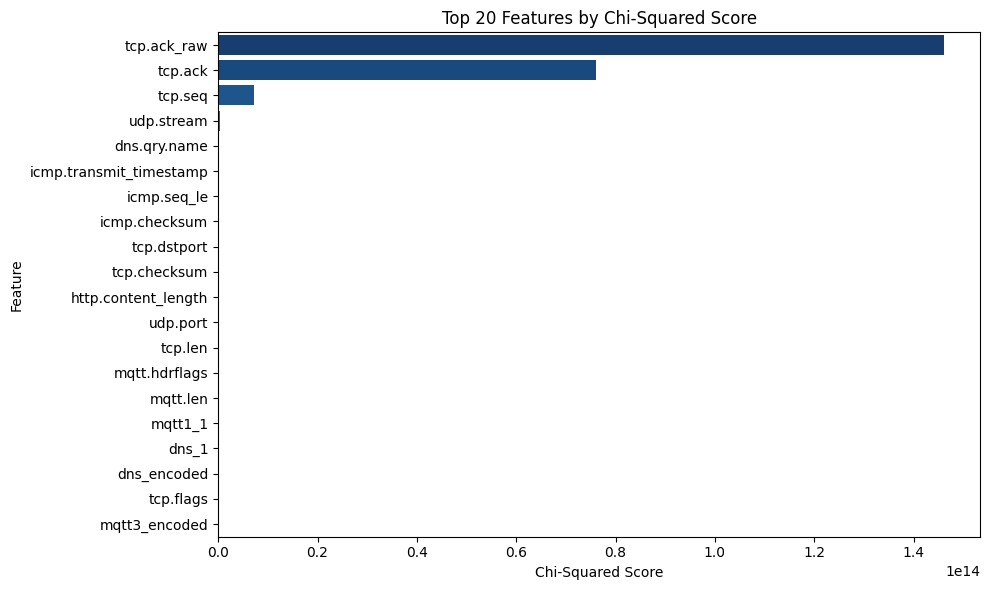

In [12]:
chi_scores_top = chi_scores.head(20)
plt.figure(figsize=(10, 6))
sns.barplot(data=chi_scores_top, x='score', y='feature', palette='Blues_r')
plt.title(f"Top 20 Features by Chi-Squared Score")
plt.xlabel("Chi-Squared Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

/tmp/ipykernel_500712/496316430.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=chi_scores_top, x='score', y='feature', palette='Blues_r')


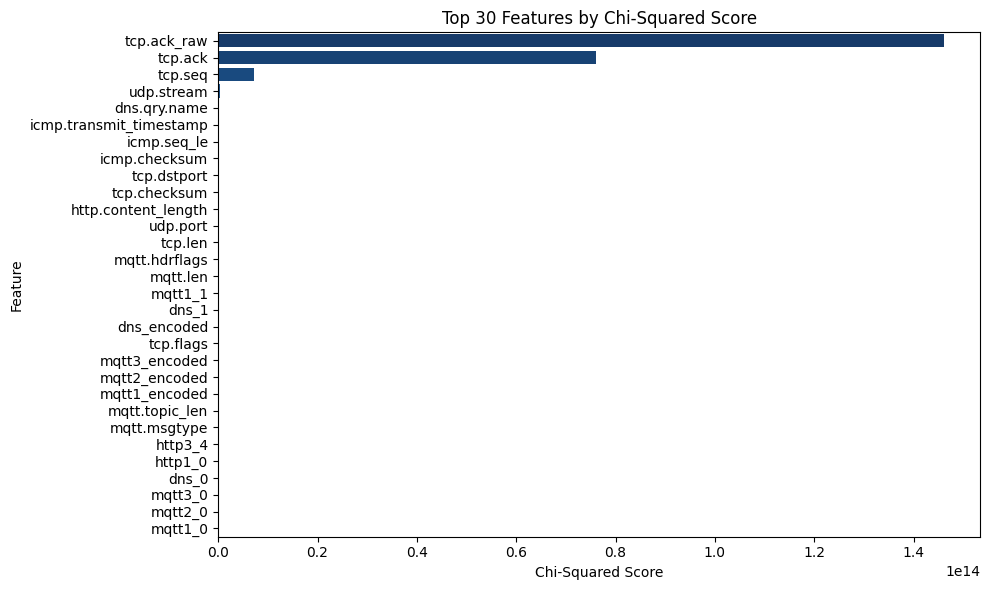

In [13]:
chi_scores_top = chi_scores.head(30)
plt.figure(figsize=(10, 6))
sns.barplot(data=chi_scores_top, x='score', y='feature', palette='Blues_r')
plt.title(f"Top 30 Features by Chi-Squared Score")
plt.xlabel("Chi-Squared Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

/tmp/ipykernel_500712/2188580838.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=chi_scores_top, x='score', y='feature', palette='Blues_r')


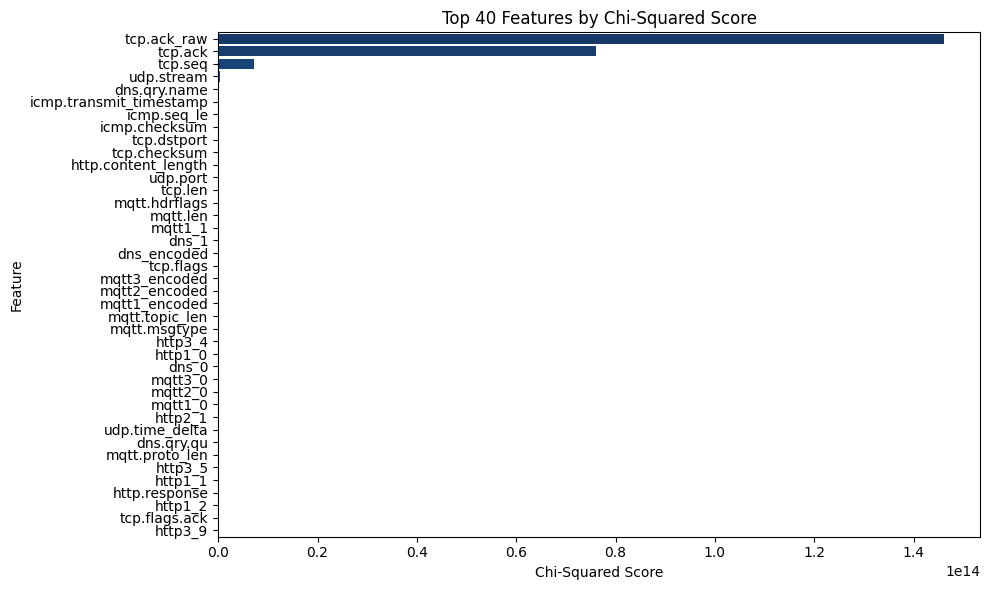

In [14]:
chi_scores_top = chi_scores.head(40)
plt.figure(figsize=(10, 6))
sns.barplot(data=chi_scores_top, x='score', y='feature', palette='Blues_r')
plt.title(f"Top 40 Features by Chi-Squared Score")
plt.xlabel("Chi-Squared Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [15]:
best_params = {
    "filters": 16,
    "kernel_size": 3,
    "dropout_rate": 0.3,
    "learning_rate": 0.0005,
    "l2_reg": 0.0001,
}

best_fit_params = {
    "epochs": 5,
    "batch_size": 16,
}

In [16]:
# Initialize the 1D CNN classifier
def model_1d_cnn(
        input_shape,
        num_classes=2,
        filters=64,
        kernel_size=3,
        pool_size=2,
        dropout_rate=0.5,
        dense_units=100,
        learning_rate=1e-3,
        optimizer="adam",
        l2_reg=0.0,
):
    _model = Sequential([
        SeparableConv1D(filters=filters,
                        kernel_size=kernel_size,
                        activation="relu",
                        kernel_regularizer=l2(l2_reg),
                        input_shape=input_shape),
        MaxPooling1D(pool_size=pool_size),
        Dropout(dropout_rate),
        Flatten(),
        Dense(dense_units, activation="relu"),
    ])

    if num_classes == 2:
        _model.add(Dense(1, activation="sigmoid"))
        loss = "binary_crossentropy"
    else:
        _model.add(Dense(num_classes, activation="softmax"))
        loss = "sparse_categorical_crossentropy"

    # choose optimiser
    if optimizer == "adam":
        opt = Adam(learning_rate=learning_rate)
    elif optimizer == "rmsprop":
        opt = RMSprop(learning_rate=learning_rate)
    elif optimizer == "sgd":
        opt = SGD(learning_rate=learning_rate, momentum=0.9)
    else:
        raise ValueError("Unknown optimiser.")

    _model.compile(optimizer=opt, loss=loss, metrics=["accuracy"])
    return _model

In [17]:
max_features = len(chi_scores['feature'].tolist())
feature_counts = list(range(10, max_features + 1, 10))  # e.g., 10, 20, ..., up to all features

results = []
num_classes = 2
for k in feature_counts:
    selected_features = chi_scores['feature'].tolist()[:k]
    X_train, X_test, y_train, y_test = train_test_split(X[selected_features], y, test_size=0.2, random_state=42)
    X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42)
    scaler = StandardScaler().fit(X_train)
    X_train = scaler.transform(X_train)
    X_val = scaler.transform(X_val)
    X_test = scaler.transform(X_test)
    input_shape = (X_train.shape[1], 1)
    model = model_1d_cnn(input_shape=input_shape,
                     num_classes=num_classes,
                     **best_params)
    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    )
    history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=best_fit_params['epochs'],
                    batch_size=best_fit_params['batch_size'],
                    callbacks=[early_stop])
    val_acc = max(history.history['val_accuracy'])
    results.append((k, val_acc))

2025-05-13 20:49:15.353776: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-05-13 20:49:15.357409: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-13 20:49:15.357717: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.so.11: cannot open shared object file: No such file or directory
2025-05-13 20:49:15.357793: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublasLt.so.11'; dlerror: libcublasLt.so.11: cannot open shared object file: No such file or directory
2025-05-13 20:49:15.357904: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Co

Epoch 1/5
85114/85114 [==============================] - 197s 2ms/step - loss: 0.2755 - accuracy: 0.8971 - val_loss: 0.1490 - val_accuracy: 0.9427
Epoch 2/5
85114/85114 [==============================] - 194s 2ms/step - loss: 0.1670 - accuracy: 0.9402 - val_loss: 0.1397 - val_accuracy: 0.9557
Epoch 3/5
85114/85114 [==============================] - 190s 2ms/step - loss: 0.1620 - accuracy: 0.9420 - val_loss: 0.1396 - val_accuracy: 0.9521
Epoch 4/5
85114/85114 [==============================] - 192s 2ms/step - loss: 0.1600 - accuracy: 0.9424 - val_loss: 0.1345 - val_accuracy: 0.9538
Epoch 5/5
85114/85114 [==============================] - 195s 2ms/step - loss: 0.1581 - accuracy: 0.9427 - val_loss: 0.1361 - val_accuracy: 0.9446
Epoch 1/5
85114/85114 [==============================] - 208s 2ms/step - loss: 0.0020 - accuracy: 0.9999 - val_loss: 1.2396e-08 - val_accuracy: 1.0000
Epoch 2/5
85114/85114 [==============================] - 205s 2ms/step - loss: 0.0011 - accuracy: 1.0000 - val_los

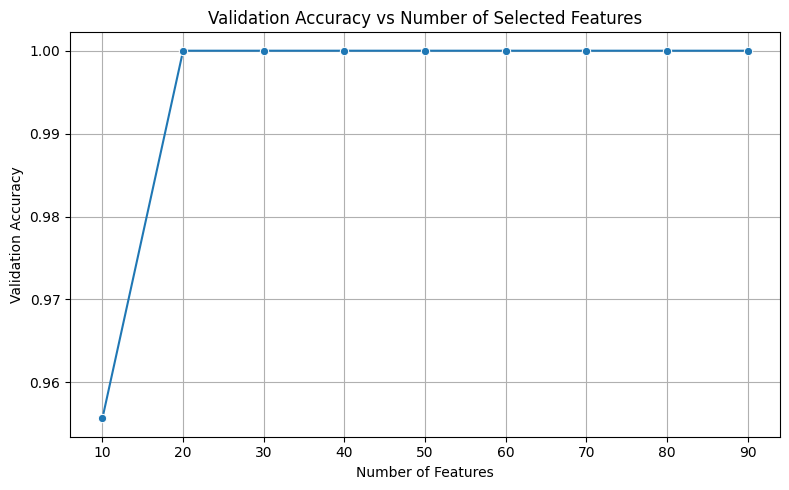

In [18]:
results_df = pd.DataFrame(results, columns=['num_features', 'val_accuracy'])
plt.figure(figsize=(8,5))
sns.lineplot(data=results_df, x='num_features', y='val_accuracy', marker='o')
plt.title("Validation Accuracy vs Number of Selected Features")
plt.xlabel("Number of Features")
plt.ylabel("Validation Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:
results_df

,num_features,val_accuracy
0,10,0.95565
1,20,1.00000
2,30,1.00000
3,40,1.00000
4,50,1.00000
5,60,1.00000
6,70,1.00000
7,80,1.00000
8,90,1.00000


In [20]:
# Convert to list of dicts
results_dict = results_df.to_dict(orient='records')

# Save to local hard drive (same folder as script, or change path as needed)
output_path = 'results/FI/results_chi_tuning.json'

with open(output_path, 'w') as f:
    json.dump(results_dict, f, indent=4)